# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba,odsetek %
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


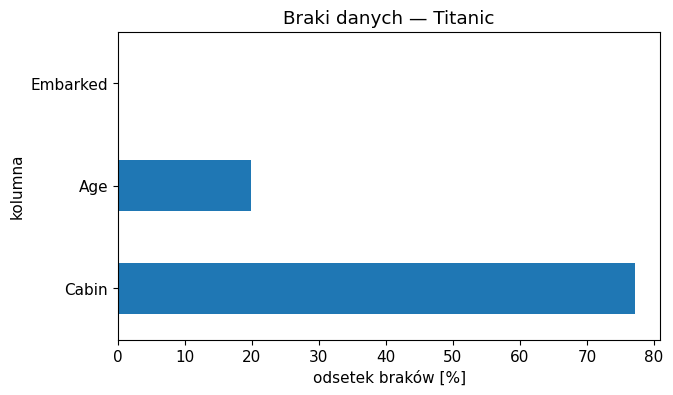

In [26]:
braki = titanic.isna().sum()
tabela = pd.DataFrame({"liczba": braki, "odsetek %": (braki / len(titanic) * 100).round(1)})
tabela = tabela[tabela["liczba"] > 0].sort_values("liczba", ascending=False)
display(tabela)

tabela["odsetek %"].plot.barh()
plt.xlabel("odsetek braków [%]")
plt.ylabel("kolumna")
plt.title("Braki danych — Titanic")
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

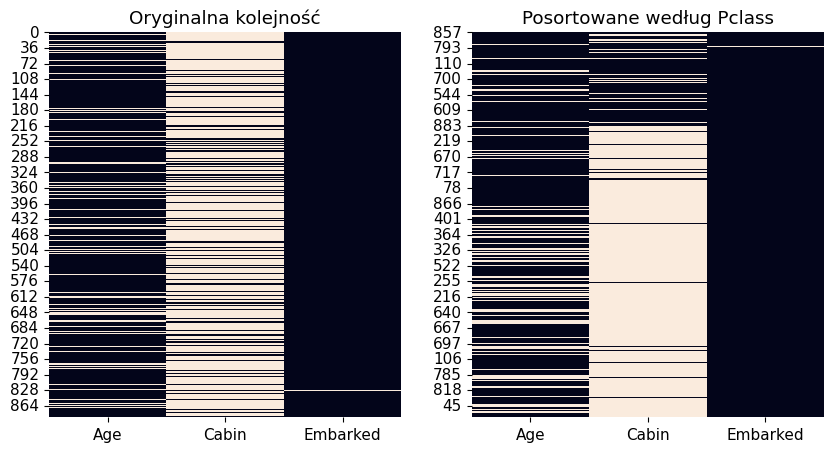

In [27]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, osie = plt.subplots(1, 2, figsize=(10, 5))
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=osie[0])
osie[0].set_title("Oryginalna kolejność")
sns.heatmap(titanic.sort_values("Pclass")[kolumny].isna(), cbar=False, ax=osie[1])
osie[1].set_title("Posortowane według Pclass")
plt.show()

*Twoja odpowiedź:* …

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64

Sex
female    16.9
male      21.5
Name: Age, dtype: float64

wiek znany       40.6
wiek nieznany    29.4
Name: Survived, dtype: float64


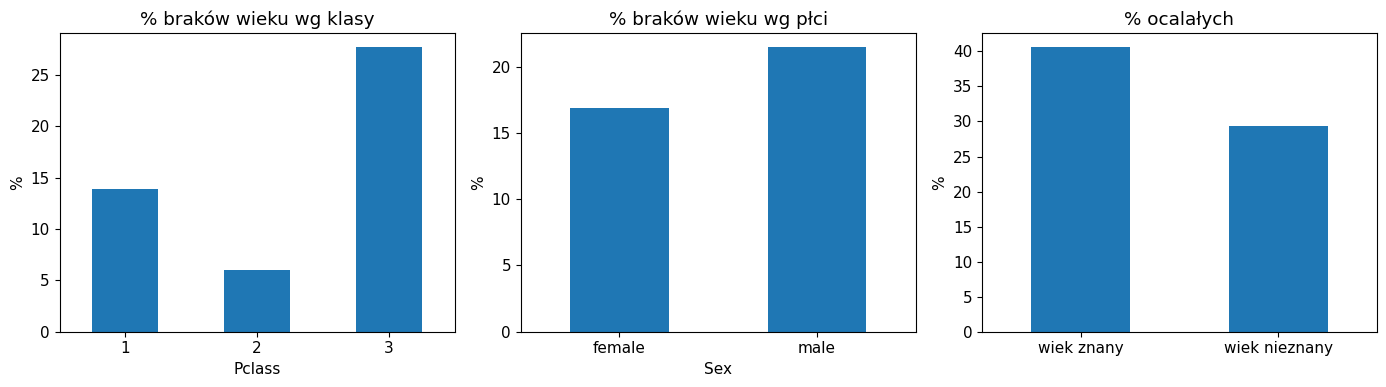

In [28]:
brak_wieku = titanic["Age"].isna()

po_klasie = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
po_plci = brak_wieku.groupby(titanic["Sex"]).mean() * 100
przezycie = titanic.groupby(brak_wieku)["Survived"].mean() * 100
przezycie.index = ["wiek znany", "wiek nieznany"]
print(po_klasie.round(1), po_plci.round(1), przezycie.round(1), sep="\n\n")

fig, osie = plt.subplots(1, 3, figsize=(14, 4))
po_klasie.plot.bar(ax=osie[0], title="% braków wieku wg klasy")
po_plci.plot.bar(ax=osie[1], title="% braków wieku wg płci")
przezycie.plot.bar(ax=osie[2], title="% ocalałych")
for o in osie:
    o.set_ylabel("%")
    o.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

*Twoja odpowiedź:*  Braki wieku to nie MCAR. W 3 klasie jest ich wyraźnie więcej niż w 1, a mężczyznom częściej brakuje wieku niż kobietom. Odsetek ocalałych jest też inny w grupie bez wieku niż ze znanym wiekiem. Gdybyśmy usunęli wiersze bez wieku, odsetek ocalałych wzrósłby, a 3 klasa byłaby niedoreprezentowana.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [29]:
warianty = {
    "bez zmian": titanic,
    "dropna(Embarked)": titanic.dropna(subset=["Embarked"]),
    "dropna(Age)": titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

tabela = pd.DataFrame({
    nazwa: {
        "liczba wierszy": len(d),
        "% ocalałych": round(d["Survived"].mean() * 100, 1),
        "% 1. klasy": round((d["Pclass"] == 1).mean() * 100, 1),
    }
    for nazwa, d in warianty.items()
}).T
tabela

,liczba wierszy,% ocalałych,% 1. klasy
bez zmian,891.0,38.4,24.2
dropna(Embarked),889.0,38.2,24.1
dropna(Age),714.0,40.6,26.1
dropna(),183.0,67.2,86.3


*Twoja odpowiedź:* Najbardziej zniekształca dropna() — przez Cabin zostaje tylko ok. 200 wierszy z 891, a w nich bardzo dużo pasażerów 1 klasy i ocalałych. Usunięcie 2 braków w Embarked prawie nic nie zmienia, usunięcie braków Age zmienia umiarkowanie.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

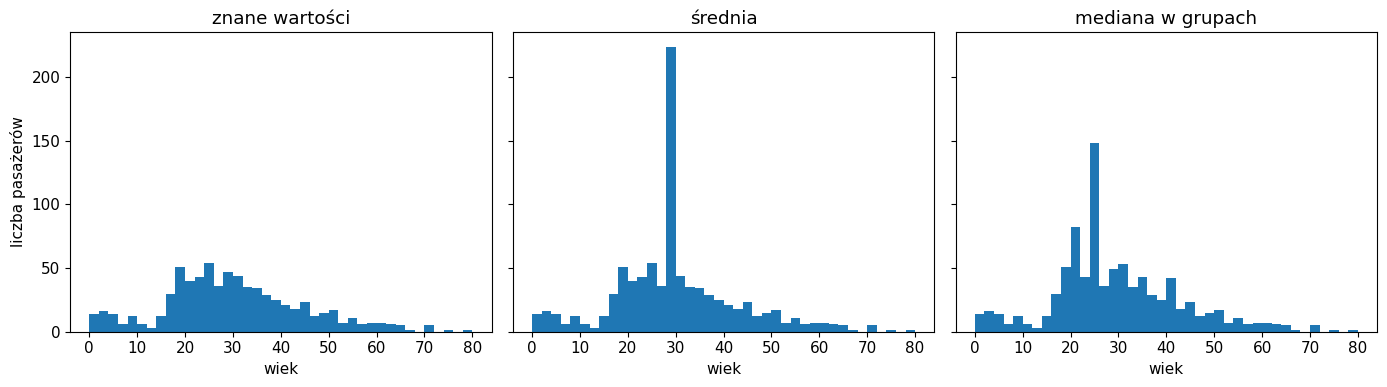

Age             14.53
wiek_srednia    13.00
wiek_grupy      13.30
dtype: float64


In [30]:
titanic["Age_brak"] = titanic["Age"].isna()

titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
titanic["wiek_grupy"] = titanic["Age"].fillna(
    titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
)

przedzialy = np.arange(0, 82, 2)
fig, osie = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for o, (kol, tytul) in zip(osie, [("Age", "znane wartości"), ("wiek_srednia", "średnia"), ("wiek_grupy", "mediana w grupach")]):
    o.hist(titanic[kol].dropna(), bins=przedzialy)
    o.set_title(tytul)
    o.set_xlabel("wiek")
osie[0].set_ylabel("liczba pasażerów")
plt.tight_layout()
plt.show()

print(titanic[["Age", "wiek_srednia", "wiek_grupy"]].std().round(2))

*Twoja odpowiedź:* obie metody zmniejszają odchylenie standardowe względem znanych wartości. Średnia tworzy jeden duży słupek w okolicy 30 lat i najbardziej spłaszcza rozkład. Mediana w grupach też tworzy słupki, ale rozkłada je na kilka wartości zależnych od klasy i płci, więc lepiej zachowuje zależność wieku od tych cech.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

In [31]:
# TODO

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [32]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print(mieszkania.dtypes)
print()
print(mieszkania.isna().sum())

id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object

id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64


*Twoja odpowiedź:* Pandas widzi tylko prawdziwe NaN: 4 w powierzchnia i 4 w rok_budowy. powierzchnia nie jest liczbowa, bo w kolumnie jest tekst "brak", jedno słowo zamienia całą kolumnę na tekst. To samo dotyczy rok_budowy i pietro.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [33]:
for kol in mieszkania.columns.drop(["id", "dzielnica"]):
    print(kol, mieszkania[kol].value_counts(dropna=False).to_dict())
    print()

miasto {'Warszawa': 9, 'Kraków': 9, 'Wrocław': 9, 'Poznań': 9, 'Gdańsk': 9}

powierzchnia {nan: 4, '0': 3, '55': 2, '48': 2, '60': 2, '62': 2, '70': 2, '72': 2, '58': 2, 'brak': 2, '65': 1, '45': 1, '52': 1, '90': 1, '68': 1, '80': 1, '75': 1, '50': 1, '66': 1, '85': 1, '54': 1, '95': 1, '56': 1, '42': 1, '78': 1, '88': 1, '64': 1, '51': 1, '69': 1, '46': 1, '82': 1, '76': 1}

liczba_pokoi {3: 18, 2: 15, 4: 7, 1: 4, 5: 1}

rok_budowy {nan: 4, 'brak': 3, '2010': 2, '2018': 2, '2020': 2, '2015': 2, '2017': 2, '2019': 2, '2016': 2, '2014': 2, '2011': 2, '2013': 2, '2001': 1, '1998': 1, '2012': 1, '1995': 1, '2005': 1, '2008': 1, '1999': 1, '2003': 1, '2009': 1, '2021': 1, '1997': 1, '2007': 1, '2002': 1, '1996': 1, '2006': 1, '2022': 1, '2000': 1, '2004': 1}

pietro {'2': 9, '1': 8, '3': 7, '4': 6, '6': 3, '0': 3, '5': 3, '-999': 2, '7': 2, 'brak': 1, '8': 1}

liczba_pieter {4: 7, 5: 6, 8: 5, 10: 4, 9: 4, 6: 4, 7: 4, 3: 3, 11: 3, 12: 2, 2: 2, 15: 1}

parking {'Tak': 34, 'Nie': 6, '?': 5}


*Twoja odpowiedź:* Oznaczenia braków: powierzchnia - NaN, "brak", 0; rok_budowy - NaN, "brak"; pietro - "brak", -999; parking i balkon - "?"; cena_m2 - -1 i -999. Pułapka: 0 w powierzchnia to brak danych, ale 0 w pietro to parter.

In [34]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
print(mieszkania.dtypes)
print()
print(mieszkania.isna().sum())

id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object

id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [35]:
print(mieszkania["stan"].value_counts())
mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
print()
print(mieszkania["stan"].value_counts())

# Uzasadnienie: "很好" to po chińsku "bardzo dobrze", więc pasuje do kategorii "Bardzo dobry".

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64

stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

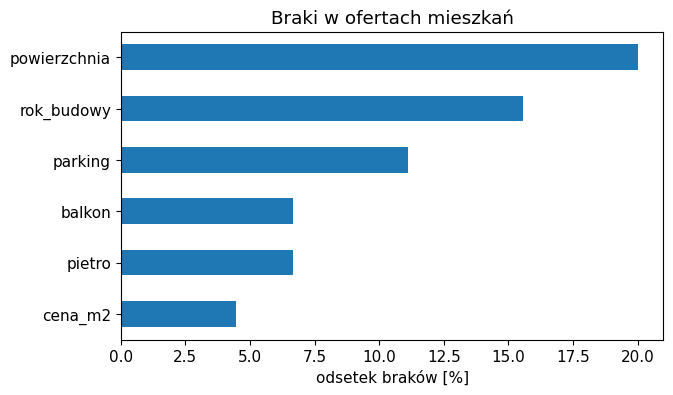

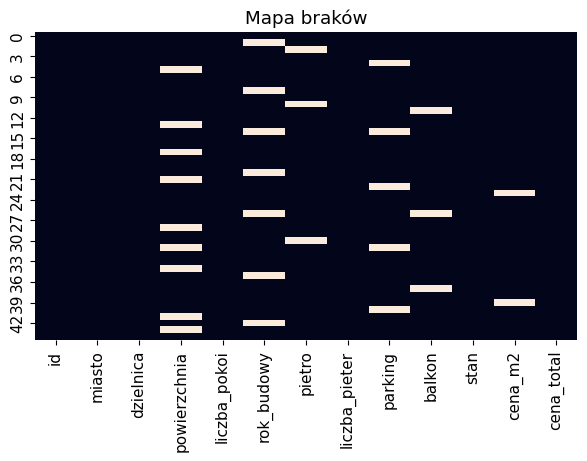

,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.00,-0.21,-0.13,-0.00,-0.13,-0.11
rok_budowy,-0.21,1.00,-0.11,0.04,0.13,-0.09
pietro,-0.13,-0.11,1.00,-0.09,-0.07,-0.06
parking,-0.00,0.04,-0.09,1.00,-0.09,-0.08
balkon,-0.13,0.13,-0.07,-0.09,1.00,-0.06
cena_m2,-0.11,-0.09,-0.06,-0.08,-0.06,1.00


In [36]:
procent = mieszkania.isna().mean() * 100
procent[procent > 0].sort_values().plot.barh()
plt.xlabel("odsetek braków [%]")
plt.title("Braki w ofertach mieszkań")
plt.show()

sns.heatmap(mieszkania.isna(), cbar=False)
plt.title("Mapa braków")
plt.show()

z_brakami = mieszkania.columns[mieszkania.isna().any()]
mieszkania[z_brakami].isna().corr().round(2)

*Twoja odpowiedź:*  Nie - korelacje między kolumnami z brakami są bliskie zera, a na mapie braki są rozrzucone po różnych wierszach. Wygląda to na braki losowe.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [37]:
kompletne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
print("cena_total == powierzchnia * cena_m2 w", (kompletne["powierzchnia"] * kompletne["cena_m2"] == kompletne["cena_total"]).mean() * 100, "% wierszy")

przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(mieszkania["cena_total"] / mieszkania["powierzchnia"])

po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
print("Braki przed:", przed.to_dict(), "→ po:", po.to_dict())

cena_total == powierzchnia * cena_m2 w 100.0 % wierszy
Braki przed: {'powierzchnia': 9, 'cena_m2': 2} → po: {'powierzchnia': 0, 'cena_m2': 0}


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [38]:
for kol in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[kol + "_brak"] = mieszkania[kol].isna()

# rok_budowy
print(mieszkania.groupby("miasto")["rok_budowy"].median())
print(mieszkania.groupby("stan")["rok_budowy"].median())
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("stan")["rok_budowy"].transform("median")
)

# pietro
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)

# parking, balkon
for kol in ["parking", "balkon"]:
    print(kol, "przed:", (mieszkania[kol].value_counts(normalize=True) * 100).round(1).to_dict())
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")
    print(kol, "po:   ", (mieszkania[kol].value_counts(normalize=True) * 100).round(1).to_dict())

print()
print("Pozostałe braki:", mieszkania.isna().sum().sum())

miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
parking przed: {'Tak': 85.0, 'Nie': 15.0}
parking po:    {'Tak': 75.6, 'Nie': 13.3, 'nieznane': 11.1}
balkon przed: {'Tak': 83.3, 'Nie': 16.7}
balkon po:    {'Tak': 77.8, 'Nie': 15.6, 'nieznane': 6.7}

Pozostałe braki: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

       powierzchnia  rok_budowy  cena_m2
count          36.0        38.0     43.0
mean           64.6      2010.3  10223.3
std            13.7         7.8   1611.7
min            42.0      1995.0   8200.0
25%            54.8      2004.2   9000.0
50%            63.0      2011.5   9800.0
75%            72.8      2016.8  11100.0
max            95.0      2022.0  15000.0

       powierzchnia  rok_budowy  cena_m2
count          45.0        45.0     45.0
mean           64.9      2010.6  10244.3
std            12.8         7.4   1623.9
min            42.0      1995.0   8200.0
25%            56.0      2006.0   9000.0
50%            62.0      2011.0   9800.0
75%            72.0      2017.0  11200.0
max            95.0      2022.0  15000.0


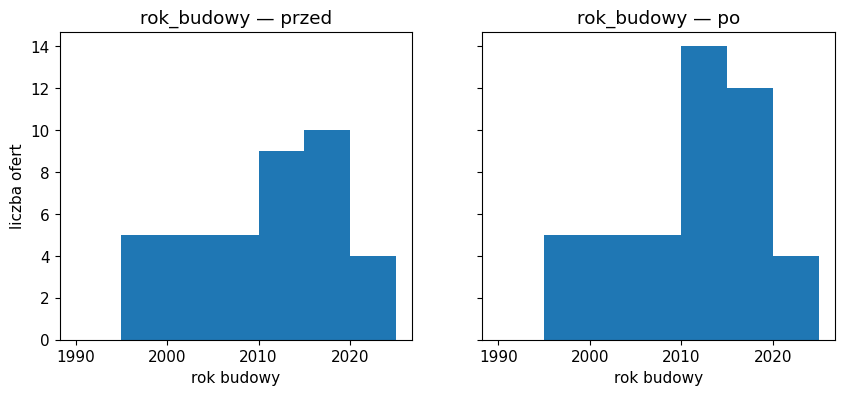

In [39]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kolumny = ["powierzchnia", "rok_budowy", "cena_m2"]

print(surowe[kolumny].describe().round(1))
print()
print(mieszkania[kolumny].describe().round(1))

przedzialy = np.arange(1990, 2030, 5)
fig, osie = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
osie[0].hist(surowe["rok_budowy"].dropna(), bins=przedzialy)
osie[0].set_title("rok_budowy — przed")
osie[1].hist(mieszkania["rok_budowy"], bins=przedzialy)
osie[1].set_title("rok_budowy — po")
for o in osie:
    o.set_xlabel("rok budowy")
osie[0].set_ylabel("liczba ofert")
plt.show()

*Twoja odpowiedź:* Średnie i odchylenia powierzchnia i cena_m2 prawie się nie zmieniły. W rok_budowy uzupełnianie dodało kilka wartości w środku rozkładu, więc histogram jest minimalnie bardziej skupiony, ale kształt się nie zmienił.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `NaN`, `"brak"`, `0` | 9 | odtworzona z `cena_total / cena_m2` | zależność jest dokładna, więc nie trzeba zgadywać |
| `cena_m2` | `-1`, `-999` | 2 | odtworzona z `cena_total / powierzchnia` | jak wyżej |
| `rok_budowy` | `NaN`, `"brak"` | 7 | mediana w grupach wg `stan` + flaga | stan mocniej różnicuje rok budowy niż miasto |
| `pietro` | `"brak"`, `-999` | 3 | `liczba_pieter // 2` + flaga | tylko 3 braki; środkowe piętro jest rozsądnym przybliżeniem |
| `parking` | `"?"` | 5 | kategoria `"nieznane"` + flaga | nie zawyżamy odsetka mieszkań z parkingiem |
| `balkon` | `"?"` | 3 | kategoria `"nieznane"` + flaga | jak wyżej |
| `stan` | wartość `"很好"` | 1 | zamiana na `"Bardzo dobry"` | to chińskie „bardzo dobrze" |


### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [40]:
# TODO

*Twoja odpowiedź:* …